
# Lecture 28 — Pipeline Hazards Summary, Precise Interrupts and Performance Evaluation

**Professor:** Dr. Janibul Bashir  
**Lecture:** [Precise Interrupts and Performance Evaluation](https://youtu.be/aMEzbfekSLY?utm_source=chatgpt.com)  
**Duration:** Approximately 47 minutes  
**Transcript:** Original English transcript retrieved

This is the last lecture of the processor-pipelining chapter.

## Lecture Overview

| Timestamp | Topic |
|---|---|
| 0:00–8:30 | Hazard summary and register renaming |
| 8:30–14:12 | Interrupts vs exceptions |
| 14:12–24:08 | Precise exceptions in pipelined processors |
| 24:08–26:16 | Saving and restoring registers |
| 26:16–37:14 | CPI numerical problems involving hazards |
| 37:14–46:52 | Pipeline speedup with unequal stage delays |

We'll start with the new concepts, then tackle the numerical questions.

---

## 1. Part 1 — Register Renaming

The professor briefly revisits **WAR** and **WAW**, explaining that they are name dependencies, unlike **RAW**.

For example:

```asm
I1: add x1, x2, x3
I2: add x1, x4, x5
```

Both instructions write `x1`, creating **WAW (Write After Write)**.

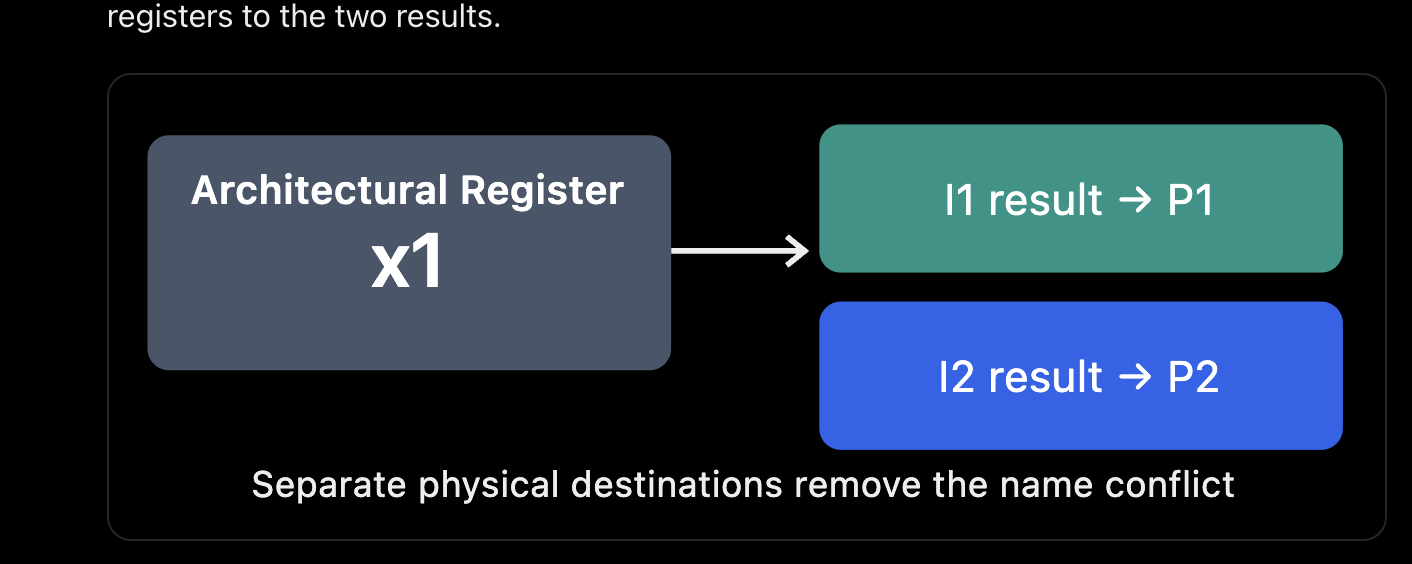
An out-of-order processor can avoid this by internally assigning different physical registers to the two results.

The processor preserves the correct architectural behavior even though the internal destinations differ.

The professor doesn't go further into the renaming hardware, so this conceptual understanding is enough here.

---

## 2. Part 2 — Interrupts vs Exceptions

**Professor's Transcript:** 8:30–14:12

Imagine a program running on a processor.

Suddenly, the processor must handle another event.

There are two important concepts:

| Feature | Interrupt | Exception |
|---|---|---|
| Origin | Usually external or asynchronous event | Usually caused by the currently executing instruction |
| Example | Keyboard/device interrupt | Illegal instruction, invalid memory access |
| Timing | Can occur independently of the current instruction | Associated with a particular instruction |
| Handler | Interrupt Service Routine (ISR) | Exception handler |

### 2.1 Key Distinction

- **Interrupt:** Something external requires processor attention.
- **Exception:** Something occurs during instruction execution that requires special handling.

Both are often handled through the processor's **trap mechanism**.

---

## 3. Part 3 — What Is a Precise Exception?

**Professor's Transcript:** 14:12–24:08

A processor pipeline may contain several instructions simultaneously.

Suppose:

| Stage | Instruction |
|---|---|
| WB | I1 |
| MEM | I2 |
| EX | I3 |
| ID | I4 |
| IF | I5 |

Now suppose **I3 causes an exception**.

### 3.1 What Should Happen to I4 and I5?

They are younger than I3, so they must not make visible changes to the program state.

For a **precise exception**, the processor must present an architectural state consistent with a clean instruction boundary.

In the usual case of an exception caused by I3:

- Older instructions **I1 and I2** are allowed to complete.
- **I3** is identified as the faulting instruction.
- Younger instructions **I4 and I5** are prevented from committing their results.
- Control transfers to the exception handler.

### 3.2 Precise Exception Diagram
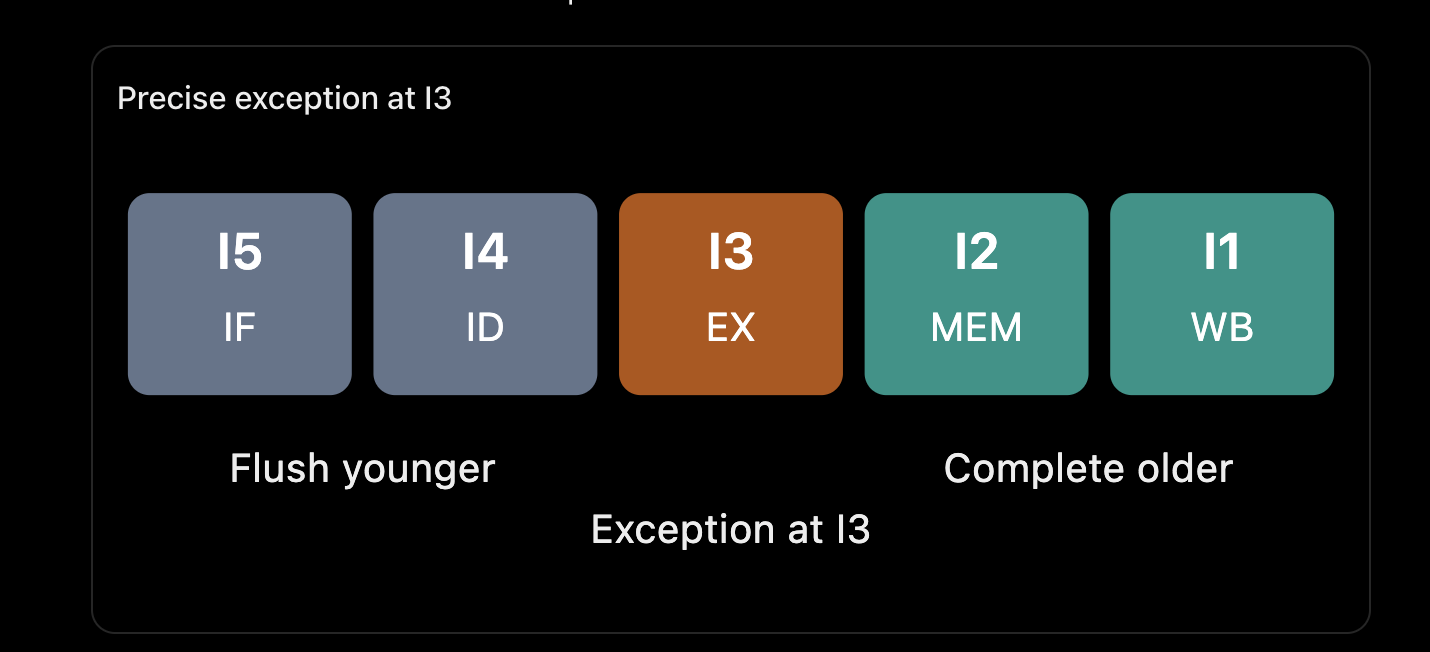


### 3.3 Exam Definition

> 📌 **Precise Exception:** A precise exception is one in which all instructions older than the faulting instruction have completed their architectural effects, while no younger instruction has made an architectural change.

This allows the processor to identify the faulting instruction and, where appropriate, resume execution correctly after handling the exception.

---

## 4. What About Saving Registers?

**Professor's Transcript:** Approximately 24:08–26:16

Before the handler uses registers needed by the interrupted program, the necessary context must be preserved.

The handler or operating system may:

1. Save register values to memory.
2. Execute the handler.
3. Restore the saved register values afterward.

This is related to **context saving and restoration**.

The professor also discusses saving register values on the **stack**.

---



# Lecture 28 — Parts 4 & 5: CPI with Hazards and Pipeline Speedup

**Professor:** Dr. Janibul Bashir  
**Part 4 Transcript:** Approximately 26:16–37:14  
**Part 5 Transcript:** Approximately 37:14–46:52

---

## 1. Lecture 28 — Part 4: Deriving the General CPI Formula

Recall:

$$
CPI=\frac{\text{Total Clock Cycles}}{\text{Instruction Count}}
$$

Suppose we execute $N$ instructions in a processor with an ideal steady-state CPI of 1.

Without hazards:

$$
\text{Total cycles}=N
$$

Now suppose $N_h$ instructions cause a hazard, each introducing $P$ extra cycles.

Then:

$$
\text{Total cycles}=N+N_hP
$$

Divide by $N$:

$$
CPI=\frac{N+N_hP}{N}
$$

$$
CPI=1+\frac{N_h}{N}P
$$

Since $\frac{N_h}{N}=f_h$, the fraction of instructions associated with that hazard:

$$
\boxed{CPI=CPI_{\text{ideal}}+f_hP}
$$

### 1.1 Variables

| Variable | Meaning |
|---|---|
| $CPI_{\text{ideal}}$ | CPI without hazards, assumed 1 here |
| $f_h$ | Hazard frequency as a fraction of instructions |
| $P$ | Additional stall cycles per hazard occurrence |
| $N$ | Total number of instructions |
| $N_h$ | Number of instructions associated with the hazard |

For multiple independent sources of stalls:

$$
\boxed{CPI=CPI_{\text{ideal}}+\sum_i f_iP_i}
$$

> 📌 **Important:** This steady-state formula ignores pipeline filling and draining and assumes the specified penalties can be added without overlap.

---

## 2. Professor's Numerical Example 1 — 10% RAW Hazards

### 2.1 Given

- Ideal CPI = 1
- 10% of instructions cause a RAW hazard
- RAW penalty = 3 cycles

### Step 1 — Convert Percentage to Fraction

$$
f_{\text{RAW}}=\frac{10}{100}=0.1
$$

### Step 2 — Apply the CPI Formula

$$
CPI=1+(0.1\times3)
$$

$$
\boxed{CPI=1.3}
$$

### 2.2 Understanding Through 100 Instructions

Assume **100 useful instructions**.

| Quantity | Cycles |
|---|---:|
| Ideal cycles | 100 |
| Extra cycles | 30 |
| Total cycles | **130** |

**Why 30 extra cycles?**

$$
100\times0.10=10\text{ RAW hazard occurrences}
$$

Each costs three cycles:

$$
10\times3=30
$$

Therefore:

$$
CPI=\frac{130}{100}=\boxed{1.3}
$$

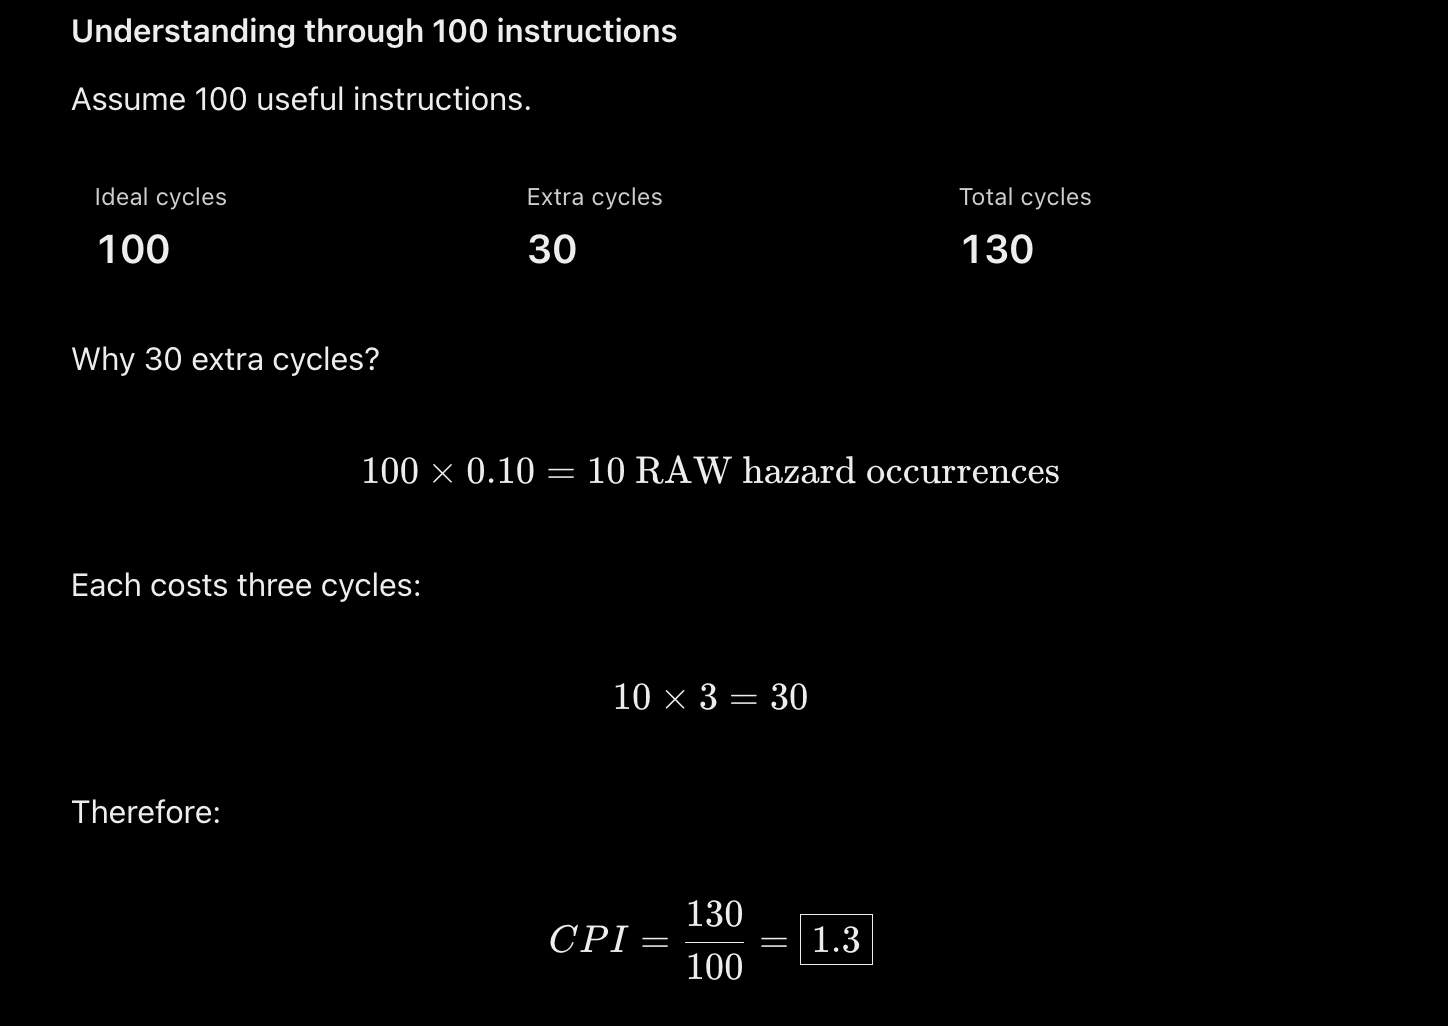
> 📝 **Transcript clarification:** The actual transcript briefly states 1.6 after deriving 1.3, but the calculation consistently establishes **1.3**, which is the correct answer.

---

## 3. Professor's Numerical Example 2 — RAW + Control Hazards

Now the professor makes the problem slightly harder.

### 3.1 Given

| Parameter | Value |
|---|---|
| Ideal CPI | 1 |
| RAW hazard frequency | 10% |
| RAW penalty | 3 cycles |
| Branch frequency | 20% |
| Control hazard penalty | 2 cycles |

### Step 1 — Start With Ideal CPI

$$
CPI_{\text{ideal}}=1
$$

### Step 2 — RAW Hazard Contribution

$$
0.10\times3=0.3
$$

### Step 3 — Branch Hazard Contribution

$$
0.20\times2=0.4
$$

### Step 4 — Add Them

$$
CPI=1+0.3+0.4
$$

$$
\boxed{CPI=1.7}
$$

### 3.2 CPI Breakdown

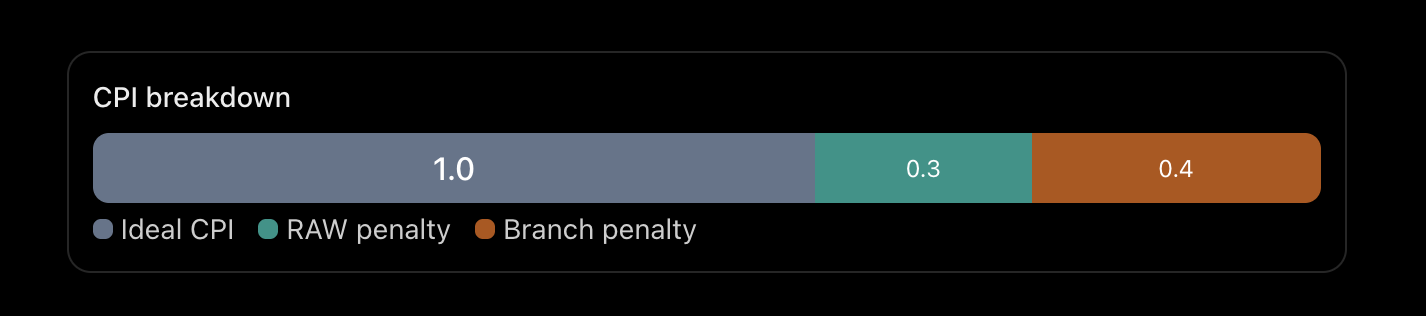

| CPI Component | Contribution |
|---|---:|
| Ideal CPI | 1.0 |
| RAW penalty | 0.3 |
| Branch penalty | 0.4 |
| **Total CPI** | **1.7** |

### 3.3 What If Branch Prediction Is Introduced?

Suppose only **10% of branches are mispredicted**, with a 2-cycle misprediction penalty and no penalty for correct predictions.

Then the branch contribution becomes:

$$
0.20\times0.10\times2=0.04
$$

So:

$$
CPI=1+0.3+0.04
$$

$$
\boxed{CPI=1.34}
$$

This additional example demonstrates why forwarding and branch prediction can substantially improve CPI.

---

## 4. Lecture 28 — Part 5: Pipeline Speedup with Unequal Stage Delays

**Professor's Transcript:** Approximately 37:14–46:52

This is the professor's final numerical problem in Lecture 28.

### 4.1 Given Data

A processor has five stages with the following execution times:

| Stage | Description | Delay |
|---|---|---:|
| IF | Instruction Fetch | 5 ns |
| ID | Instruction Decode / Operand Fetch | 6 ns |
| EX | Execute | 11 ns |
| MEM | Memory Access | 6 ns |
| WB | Writeback | 5 ns |

Each pipeline register introduces an additional **1 ns overhead**.

**Find the speedup of the pipelined processor compared with the non-pipelined processor, assuming a very large instruction count and no hazards.**

---

## 5. Step 1 — Non-Pipelined Processor

In the professor's non-pipelined model, an instruction passes sequentially through all five stages before the next instruction begins.

### Total Instruction Time

$$
T_{\text{nonpipe}}=5+6+11+6+5
$$

$$
\boxed{T_{\text{nonpipe}}=33\text{ ns/instruction}}
$$

Notice that we do not add pipeline-register overhead, because the comparison assumes the non-pipelined datapath does not use those interstage pipeline registers.

---

## 6. Step 2 — Pipelined Processor

For a pipeline, every stage must finish its work within one clock period.

The clock therefore needs to be long enough for the **slowest stage**, including pipeline-register overhead.

### 6.1 Pipeline Clock Period Formula

$$
\boxed{
T_{\text{clk}}=\max(t_1,t_2,\ldots,t_k)+t_{\text{latch}}
}
$$

Where:

| Variable | Meaning |
|---|---|
| $t_i$ | Combinational delay of stage $i$ |
| $k$ | Number of stages |
| $t_{\text{latch}}$ | Pipeline-register overhead |

### 6.2 Find the Slowest Stage

Here:

$$
\max(5,6,11,6,5)=11\text{ ns}
$$

The **EX stage** is the slowest, so it determines the pipeline clock period.

$$
T_{\text{clk}}=11+1
$$

$$
\boxed{T_{\text{clk}}=12\text{ ns}}
$$

### 6.3 Stage Delays Compared with the Pipeline Clock

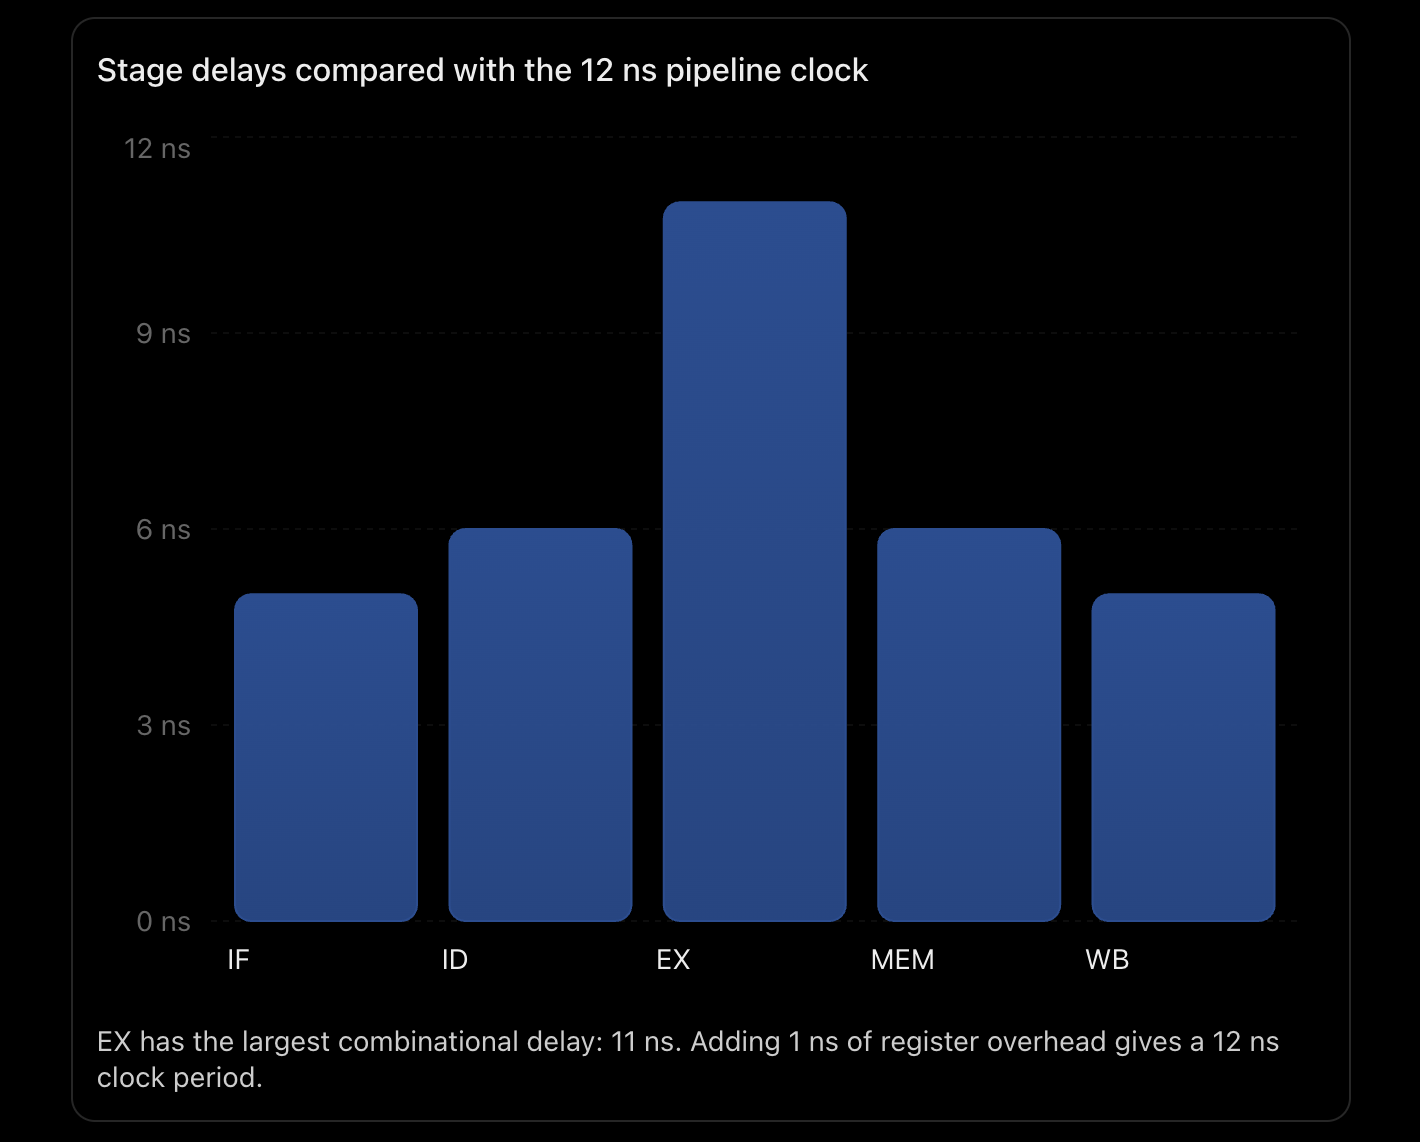

EX has the largest combinational delay: 11 ns.

Adding 1 ns of register overhead gives a 12 ns clock period.

> 📌 **Key concept:** Not every stage actually takes 12 ns of computation. All stages are simply allocated the same 12 ns clock period, even if they finish earlier.

---

## 7. Step 3 — Calculate Speedup

Speedup is defined as:

$$
\boxed{S=\frac{T_{\text{nonpipe}}}{T_{\text{pipe}}}}
$$

For a sufficiently large instruction sequence, the pipeline approaches **one completed instruction every clock cycle**.

So its throughput approaches:

$$
\frac{1\text{ instruction}}{12\text{ ns}}
$$

The non-pipelined processor completes one instruction every 33 ns.

Therefore:

$$
S=\frac{33}{12}
$$

$$
\boxed{S=2.75}
$$

### Final Answer

$$
\boxed{2.75\times\text{ speedup}}
$$

The pipelined processor has approximately **2.75 times the instruction throughput** of the non-pipelined processor under the stated assumptions.

> 📝 **Transcript clarification:** The transcript contains a verbal arithmetic slip near the end of this calculation. The correct result is **33/12 = 2.75**, not 33/2.

### 7.1 Why Isn't the Speedup 5×?

We have five pipeline stages, so an ideal pipeline might approach a fivefold speedup.

However, our stages are **not balanced**.

The EX stage takes 11 ns, whereas IF and WB only take 5 ns.

The faster stages spend part of each clock period idle, waiting for the slowest stage.

Additionally, the pipeline registers introduce overhead.

Therefore:

$$
\boxed{\text{Actual speedup}<5}
$$

---

## 8. Important Extension — What If There Are Only 10 Instructions?

The professor uses a large instruction count, so he ignores pipeline filling and draining.

But your exam could give a finite instruction count.

For $n$ instructions and $k$ stages:

$$
T_{\text{pipe}}=(n+k-1)T_{\text{clk}}
$$

### 8.1 Pipelined Execution

For:

$$
n=10,\qquad k=5
$$

Substitute:

$$
T_{\text{pipe}}=(10+5-1)\times12
$$

$$
=\boxed{168\text{ ns}}
$$

### 8.2 Non-Pipelined Execution

$$
T_{\text{nonpipe}}=10\times33
$$

$$
\boxed{T_{\text{nonpipe}}=330\text{ ns}}
$$

### 8.3 Speedup

$$
S=\frac{330}{168}
$$

$$
\boxed{S\approx1.96}
$$

### Comparison

| Instruction Count | Speedup |
|---|---:|
| 10 instructions | **1.96×** |
| Very large instruction count | **2.75×** |

> 📌 **Important:** This is why you must check whether a speedup question specifies a finite instruction count or assumes a very large number of instructions.

---

## 9. Lecture 28 — Final Formula Sheet

| Quantity | Formula |
|---|---|
| CPI | $\dfrac{\text{Total Cycles}}{\text{Instruction Count}}$ |
| CPI with hazards | $CPI_{\text{ideal}}+\sum_i f_iP_i$ |
| Pipeline clock period | $\max(t_i)+t_{\text{latch}}$ |
| Non-pipelined instruction time | $\sum_i t_i$ |
| Pipeline execution time | $(n+k-1+\text{stalls})T_{\text{clk}}$ |
| Non-pipelined execution time | $n\sum_i t_i$ |
| Speedup | $\dfrac{T_{\text{nonpipe}}}{T_{\text{pipe}}}$ |
| IPC | $\dfrac{1}{CPI}$ |

---

**Lecture 28 completes the processor-pipelining chapter.**

According to the professor's closing remarks, **Lecture 29 begins the memory-system chapter**.
